In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision
from torchvision import transforms
import timm
import os
from skimage.io import imread
import torchxrayvision as xrv

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

# Loading the data

In [2]:
# Custom normalize function
def normalize(img, maxval, reshape=False):
    """Scales images to be roughly [-1024 1024]."""

    if img.max() > maxval:
        raise Exception("max image value ({}) higher than expected bound ({}).".format(img.max(), maxval))

    # img = (2 * (img.astype(np.float32) / maxval) - 1.) * 1024
    
    img = img.astype(np.uint8)
    if reshape:
        # Check that images are 2D arrays
        if len(img.shape) > 2:
            img = img[:, :, 0]
        if len(img.shape) < 2:
            print("error, dimension lower than 2 for image")

        # add color channel
        img = img[None, :, :]

    return img

In [3]:
# Custom dataset
class COVID19Dataset(xrv.datasets.COVID19_Dataset):
    def __getitem__(self, idx):
        sample = {"idx": idx, "lab": self.labels[idx]}
        imgid = self.csv['filename'].iloc[idx]
        img_path = os.path.join(self.imgpath, imgid)
        img = imread(img_path)

        sample["img"] = normalize(img, maxval=255, reshape=True)

        if self.semantic_masks:
            sample["semantic_masks"] = self.get_semantic_mask_dict(imgid, sample["img"].shape)

        sample = xrv.datasets.apply_transforms(sample, self.transform)
        sample = xrv.datasets.apply_transforms(sample, self.data_aug)

        sample["img"] = sample["img"].astype(np.uint8)

        sample["img"] = torch.Tensor(sample["img"]) / 255

        # standartization
        sample["img"] = (sample["img"] - 0.5268) / 0.2224

        sample['lab'] = 1 if sample['lab'][2] else 0
        return sample["img"], sample["lab"]


In [4]:
input_size = 224

path = 'C:/Users/Main/Documents/Medical Datasets/covid-chestxray-dataset'

In [5]:
mean = 0.5268
std  = 0.2224

transform = transforms.Compose([xrv.datasets.XRayCenterCrop(), xrv.datasets.XRayResizer(input_size)])

In [6]:
dataset = COVID19Dataset(csvpath=f'{path}/metadata.csv', imgpath=f'{path}/images/', views=['PA'], transform=transform)

train_dataset, val_dataset, test_dataset = random_split(dataset, [270, 30, 32], generator=torch.Generator().manual_seed(42))

In [7]:
dataset.pathologies

['Aspergillosis',
 'Bacterial',
 'COVID-19',
 'Chlamydophila',
 'Fungal',
 'H1N1',
 'Influenza',
 'Klebsiella',
 'Legionella',
 'Lipoid',
 'MERS-CoV',
 'MRSA',
 'Mycoplasma',
 'No Finding',
 'Nocardia',
 'Pneumocystis',
 'Pneumonia',
 'SARS',
 'Staphylococcus',
 'Streptococcus',
 'Tuberculosis',
 'Varicella',
 'Viral']

In [8]:
# df = pd.read_csv(f'{path}/metadata.csv')

# df_fn = df[(df.view == 'PA') & ~((df.finding == "todo") | (df.finding == "Unknown"))].filename.copy()

# df_fn = df_fn.to_frame()
# df_fn.reset_index(inplace=True)
# df_fn.drop(columns=df_fn.columns[0], inplace=True)
# df_fn['labels'] = dataset.labels[:, 2]

# # df_fn.to_csv(f'{path}/metadata_short.csv')

In [9]:
train_loader    = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
val_loader      = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=True, num_workers=0)
test_loader     = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)

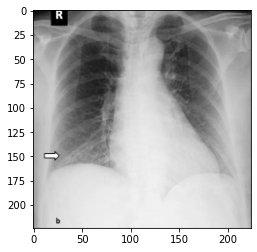

In [10]:
# Test Loader
dataiter = iter(train_loader)
sample_img, sample_label = dataiter.next()

plt.imshow(sample_img[0].permute(1, 2, 0).detach().numpy(), cmap="Greys_r")

In [28]:
sample_img.shape

torch.Size([32, 1, 224, 224])

In [11]:
# dict(zip(dataset.pathologies, sample_label[0]))

# Loading the model

In [12]:
# timm.list_models(pretrained=True)

## VIT TINY

In [20]:
model = timm.create_model('vit_tiny_patch16_224', pretrained=True, in_chans=1, num_classes=2).to(device)

In [14]:
param_name = [name for name,_ in model.named_parameters()] # All parameters name
layer_name = [name for name,_ in model.named_modules()] # All layers name

In [58]:
# Freeze
for param in model.parameters():
        param.requires_grad = False
model.head.weight.requires_grad = True
model.head.bias.requires_grad   = True

In [66]:
# UnFreeze
for param in model.parameters():
        param.requires_grad = True

## Training Loop

In [21]:
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)


optimizer_sgd = torch.optim.SGD(model.parameters(), lr=1e-3, momentum=0.9)
# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer_sgd, step_size=7, gamma=0.1)

In [24]:
num_epochs = 24

In [23]:
n_total_steps = len(train_loader)

def train_one_epoch(criterion, optimizer):
    running_loss = 0.
    last_loss = 0.

    for i, (features, labels) in enumerate(train_loader):

        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(features.float())

        loss = criterion(outputs, labels.long())
        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        if i == n_total_steps - 1:
            last_loss = running_loss / n_total_steps
            running_loss = 0.

    return last_loss

In [25]:
loss_val_list   = []
loss_train_list = []

# Validation Loop
for epoch in range(num_epochs):

    model.train(True)

    avg_loss = train_one_epoch(criterion, optimizer_sgd)

    exp_lr_scheduler.step()

    model.train(False)

    running_loss_val = 0.0

    for i, (features_val, labels_val) in enumerate(val_loader):
                
        features_val = features_val.to(device)
        labels_val = labels_val.to(device)

        outputs_val = model(features_val.float())

        loss_val = criterion(outputs_val, labels_val.long())

        running_loss_val += loss_val
    
    avg_loss_val = running_loss_val / (i + 1)

    loss_train_list.append(avg_loss)
    loss_val_list.append(avg_loss_val.item())

    print(f'EPOCH {epoch + 1}: LOSS train {avg_loss} valid {avg_loss_val}')


EPOCH 1: LOSS train 0.7388166189193726 valid 0.6893172860145569
EPOCH 2: LOSS train 0.5189511809084151 valid 1.3338253498077393
EPOCH 3: LOSS train 0.5996674787667062 valid 0.6391734480857849
EPOCH 4: LOSS train 0.29550592766867745 valid 0.6011973023414612
EPOCH 5: LOSS train 0.19115464430716303 valid 0.8184008002281189
EPOCH 6: LOSS train 0.06085809051162667 valid 0.6472310423851013
EPOCH 7: LOSS train 0.026374448685803346 valid 0.6606089472770691
EPOCH 8: LOSS train 0.008157189469784498 valid 0.6402285099029541
EPOCH 9: LOSS train 0.006550563318240974 valid 0.6256012320518494
EPOCH 10: LOSS train 0.004737700064045687 valid 0.6248304843902588
EPOCH 11: LOSS train 0.004114502471768194 valid 0.6232743859291077
EPOCH 12: LOSS train 0.0033685145382252005 valid 0.6247831583023071
EPOCH 13: LOSS train 0.0029533669197311005 valid 0.6250527501106262
EPOCH 14: LOSS train 0.0028422543675535256 valid 0.6242840886116028
EPOCH 15: LOSS train 0.0025446132963730227 valid 0.6239842772483826
EPOCH 16:

## Testing Loop

In [26]:
# Simple Testing Loop

def testing_loop(model, test_loader):
    with torch.no_grad():
        n_correct = 0
        n_samples = 0

        for features, labels in test_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = model(features.float())
            _, predictions = torch.max(outputs, 1)
            n_samples += labels.shape[0]
            n_correct += (predictions == labels).sum().item()

        return 100 * n_correct / n_samples

print(testing_loop(model, test_loader))

78.125


Testing Results with 10 epochs, lr [0.01, 0.001, 0.0001]:
* ViT tiny - 78.125, 75.0, 65.625
* ViT base - 62.5  , 75.0, 